# Study Donuts for AOS

**Author:** Aaron Roodman
**Date Created:** 2025-10-30  
**Last Modified:** 2026-01-26  
**Status:** [Draft]  
**Related Notebooks:** []  
**Keywords:** [AOS,Intrinsic Wavefront] 

## Purpose & Objectives

Fit some Full Array Model donuts.  

### Primary Goal


### Specific Objectives

### Context

This notebook was never really finished!

## Change Log

| Date | Change | Notes |
|------|--------|-------|
| 2025-10-25 | Initial creation | Started analysis |
| 2026-01-26 | Clean up | |

## Table of Contents

- [Setup & Imports](#setup)
- [Data Loading](#data)
- [Analysis](#analysis)
- [Results](#results)
- [Conclusions](#conclusions)
- [Next Steps](#next-steps)

<a id='setup'></a>
## Setup & Imports


In [2]:
import numpy as np
from lsst.daf.butler import Butler
from matplotlib import pyplot as plt
from scipy.optimize import least_squares


In [11]:
from lsst.ts.wep.task import CalcZernikesTask, CalcZernikesTaskConfig, EstimateZernikesDanishTask, DonutStamps
from lsst.ts.wep.utils import getTaskInstrument
from lsst.ts.wep.estimation import WfEstimator

<a id='data'></a>
## Data Loading

### Data Sources
- **Source 1:** Bryce's collections of Full Array Mode
- **Source 2:** 

### Data Description


In [3]:
twenty_donut_collection = 'u/brycek/aos_cwfs_danish_dense'
butler = Butler('/repo/main')

In [4]:
camera = butler.get('camera', dataId={'instrument': 'LSSTCam'}, collections=twenty_donut_collection)

In [5]:
camera_id_map = camera.getIdMap()

In [6]:
extra_detector_id = 195
extra_detector_name = camera_id_map[extra_detector_id].getName()
exposure_id = visit_id = 2025050700661
data_id_1 = {'instrument': 'LSSTCam', 'detector': extra_detector_id, 'visit': visit_id, 'exposure': exposure_id}

In [7]:
ds_intra = butler.get('donutStampsIntra', dataId=data_id_1, collections=twenty_donut_collection)
ds_extra = butler.get('donutStampsExtra', dataId=data_id_1, collections=twenty_donut_collection)
zernikes = butler.get('zernikes', dataId=data_id_1, collections=twenty_donut_collection)

In [8]:
donut_idx = 0

Text(0.5, 1.0, 'Extra-focal: Idx=0')

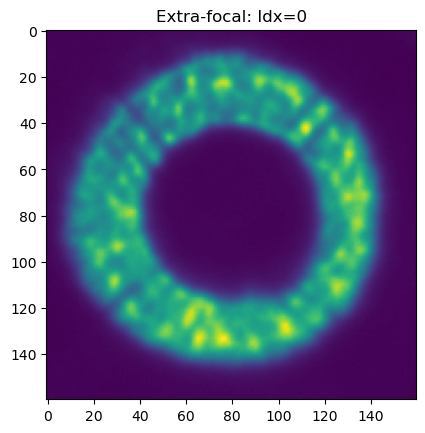

In [9]:
plt.imshow(ds_extra[donut_idx].stamp_im.image.array)
plt.title(f'Extra-focal: Idx={donut_idx}')

Text(0.5, 1.0, 'Intra-focal: Idx=0')

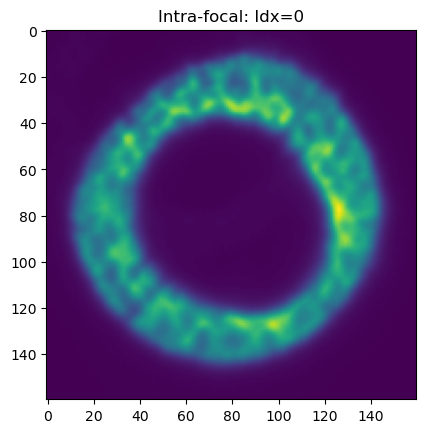

In [10]:
plt.imshow(ds_intra[donut_idx].stamp_im.image.array)
plt.title(f'Intra-focal: Idx={donut_idx}')

## Pull out Danish

### Load configurations from `ts_wep`

In [12]:
config = CalcZernikesTaskConfig()

In [13]:
config.estimateZernikes.retarget(EstimateZernikesDanishTask)

In [14]:
## Current ts_wep danish pipeline

## These are more about selecting which donuts to use
config.donutStampSelector.maxSelect = 20
config.donutStampSelector.maxFracBadPixels = 2.0e-4
config.donutStampSelector.useCustomSnLimit = True
config.donutStampSelector.minSignalToNoise = 100

## These are options that affect the fitting inside danish
binFactor = 2
config.estimateZernikes.binning = binFactor
nollIndices = np.arange(4, 29)
config.estimateZernikes.nollIndices = list(nollIndices)
config.estimateZernikes.lstsqKwargs = {'ftol': 1.0e-3, 'xtol': 1.0e-3, 'gtol': 1.0e-3}

## This will give more information on the models inside each iteration of the fit.
config.estimateZernikes.saveHistory = False

In [15]:
task = CalcZernikesTask(config=config)

#### Prepare the donut images for danish

We use the structure that is in `ts_wep/estimation/danish` found [here](https://github.com/lsst-ts/ts_wep/blob/develop/python/lsst/ts/wep/estimation/danish.py).

In [15]:
camName = 'LSSTCam'
detectorName = extra_detector_name
instrument = getTaskInstrument(
    camName,
    detectorName,
    task.estimateZernikes.config.instConfigFile,
)

# Create the wavefront estimator
wfEst = WfEstimator(
    algoName=task.estimateZernikes.wfAlgoName,
    algoConfig=task.estimateZernikes.wfAlgoConfig,
    instConfig=instrument,
    nollIndices=task.estimateZernikes.config.nollIndices,
    startWithIntrinsic=task.estimateZernikes.config.startWithIntrinsic,
    returnWfDev=task.estimateZernikes.config.returnWfDev,
    units="um",
    saveHistory=task.estimateZernikes.config.saveHistory,
)

In [16]:
ds_extra_single = DonutStamps(ds_extra[donut_idx:donut_idx+1])
ds_intra_single = DonutStamps(ds_intra[donut_idx:donut_idx+1])

In [17]:
I1 = ds_extra_single[0].wep_im
I2 = ds_intra_single[0].wep_im

In [18]:
print(I1.fieldAngle)
print(I1.bandLabel)
print(nollIndices)

[-1.09799835  1.12001774]
BandLabel.LSST_R
[ 4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27
 28]


In [19]:
zkIntrinsicI1 = instrument.getIntrinsicZernikes(
    *I1.fieldAngle,
    I1.bandLabel,
    nollIndices,
)
zkIntrinsicI2 = instrument.getIntrinsicZernikes(
    *I2.fieldAngle,
    I2.bandLabel,
    nollIndices,
)

In [20]:
print(zkIntrinsicI1)

[ 4.17729732e-08  8.50754212e-09  1.68934537e-10  1.26385155e-08
 -1.23900448e-08  7.09295058e-08  7.52852997e-08 -1.41761551e-08
 -3.62188584e-10 -1.82398534e-08  2.83784237e-09 -1.12746006e-10
  2.71811940e-09 -2.77262688e-09 -1.42372261e-08 -1.34135010e-08
 -4.80586781e-10  5.30830291e-10 -5.27176477e-09 -1.28020951e-08
 -2.54211815e-10 -3.37200518e-11  8.48741196e-10  8.13217385e-12
  4.84830090e-13]


In [21]:
# plot Intrinsic

In [22]:
# Define limits
xmin, xmax = -1.5, 1.5  # x-axis limits
ymin, ymax = -1.5, 1.5  # y-axis limits
num_points = 100     # Number of points along each axis

# Create linearly spaced points for x and y
x = np.linspace(xmin, xmax, num_points)
y = np.linspace(ymin, ymax, num_points)

# Create the meshgrid
X, Y = np.meshgrid(x, y)
R = np.sqrt(X**2 + Y**2)
selpts = (R<1.5)
X = X[selpts].flatten()
Y = Y[selpts].flatten()
R = R[selpts].flatten()


In [36]:
type(I2.bandLabel)
print(I2.bandLabel)

BandLabel.LSST_R


In [42]:
from lsst.ts.wep.utils import BandLabel

In [43]:
iband = BandLabel.LSST_I

In [44]:

z4s = []
for i in range(len(X)):
    x = X[i]
    y = Y[i]
    zkIntrinsics = instrument.getIntrinsicZernikes(
        x,y,
        iband,
        nollIndices,
    )
    z4s.append(zkIntrinsics[0])

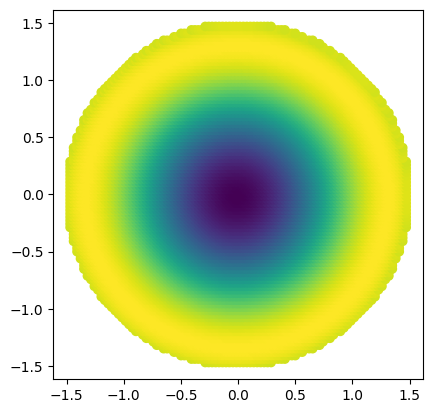

In [45]:
f,ax = plt.subplots(1,1)
_ = ax.scatter(X,Y,c=z4s)
ax.set_aspect('equal')

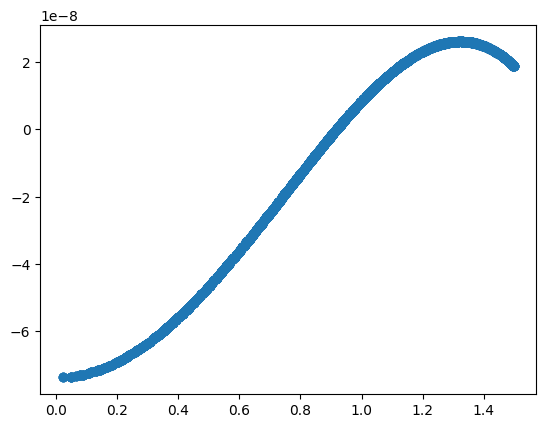

In [46]:
f,ax = plt.subplots(1,1)
_ = ax.scatter(R,z4s-np.mean(z4s))

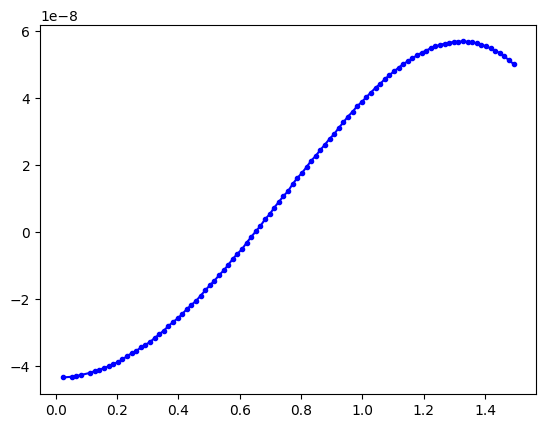

In [47]:
# Define the bins for x
from scipy.stats import binned_statistic
num_bins = 100  # Number of bins
bins = np.linspace(0.0,1.5, num_bins + 1)  # Create bins

# Calculate the mean of y in each bin
bin_means, bin_edges, binnumber = binned_statistic(R, z4s, statistic='mean', bins=bins)

# Calculate the mid points of each bin
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])

# check for nan
badpt = np.isnan(bin_means)
bin_means = bin_means[~badpt]
bin_centers = bin_centers[~badpt]

# Create the binned profile plot
f,ax = plt.subplots(1,1)
_ = ax.plot(bin_centers, bin_means, marker='.', label='Mean Z4', color='b', linestyle='-')


In [48]:
print(bin_means)

[-4.32873467e-08 -4.30712566e-08 -4.28554124e-08 -4.25321390e-08
 -4.19086539e-08 -4.13513998e-08 -4.09666719e-08 -4.04973786e-08
 -3.99302451e-08 -3.92943607e-08 -3.87308323e-08 -3.78891002e-08
 -3.69582610e-08 -3.60782726e-08 -3.54145519e-08 -3.43409475e-08
 -3.35505498e-08 -3.27160518e-08 -3.15280104e-08 -3.04215893e-08
 -2.93193114e-08 -2.79600737e-08 -2.67757411e-08 -2.56983127e-08
 -2.43742117e-08 -2.29304002e-08 -2.16419338e-08 -2.04949925e-08
 -1.89182563e-08 -1.73623348e-08 -1.58060257e-08 -1.44714755e-08
 -1.28265282e-08 -1.14319836e-08 -9.74995196e-09 -7.95651644e-09
 -6.44021371e-09 -5.04772642e-09 -3.15895418e-09 -1.41711162e-09
  2.54885493e-10  1.84557555e-09  3.84011000e-09  5.30595167e-09
  7.30800368e-09  9.00304993e-09  1.07325642e-08  1.21997463e-08
  1.43206029e-08  1.60950168e-08  1.75874293e-08  1.93241037e-08
  2.12286590e-08  2.26739281e-08  2.44432574e-08  2.60342780e-08
  2.77357378e-08  2.91491020e-08  3.10091634e-08  3.26337436e-08
  3.43954430e-08  3.58009

[[Model]]
    Model(polynomial_model)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 22
    # data points      = 97
    # variables        = 6
    chi-square         = 9.0530e-19
    reduced chi-square = 9.9484e-21
    Akaike info crit   = -4461.71090
    Bayesian info crit = -4446.26264
    R-squared          = 0.99999283
[[Variables]]
    c0: -4.3436e-08 +/- 8.1978e-11 (0.19%) (init = 0)
    c1:  1.3886e-09 +/- 9.9659e-10 (71.77%) (init = 1)
    c2:  1.1111e-07 +/- 3.8803e-09 (3.49%) (init = 1)
    c3:  1.3827e-08 +/- 6.3411e-09 (45.86%) (init = 0)
    c4: -5.0372e-08 +/- 4.5612e-09 (9.06%) (init = 0)
    c5:  6.4583e-09 +/- 1.1924e-09 (18.46%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(c4, c5) = -0.9952
    C(c3, c4) = -0.9926
    C(c2, c3) = -0.9872
    C(c3, c5) = +0.9762
    C(c1, c2) = -0.9729
    C(c2, c4) = +0.9613
    C(c2, c5) = -0.9315
    C(c1, c3) = +0.9263
    C(c0, c1) = -0.9082
    C(c1, c4) = -0.8793
    C(c1,

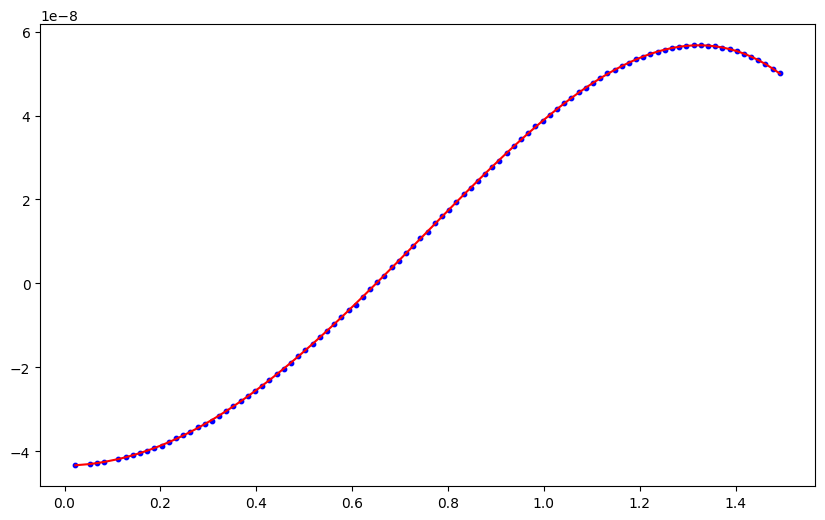

In [49]:
# Define a polynomial model (2nd degree polynomial in this case)

from lmfit import Model
def polynomial_model(x, c0,c1,c2,c3,c4,c5):
    return c5 * x**5 + c4 * x**4 + c3 * x**3 + c2 * x**2 + c1 * x + c0

# Create a Model object
model = Model(polynomial_model)

# Fit the model to the data
params = model.make_params(c0=0,c1=1.,c2=1.,c3=0.,c4=0.,c5=0.)  # Initial guesses for parameters
result = model.fit(bin_means, params, x=bin_centers)


# Print the fitting report
print(result.fit_report())

# Extract the best-fit values
best_fit_y = result.best_fit

# Plot original data and the fitted curve
plt.figure(figsize=(10, 6))
plt.scatter(bin_centers, bin_means, label='Data', color='blue', s=10)
plt.plot(bin_centers, best_fit_y, label='Fitted Polynomial', color='red')

In [50]:
parlist = []
for i in range(5+1):
    parname = 'c%d' % (i)
    print(parname,result.params[parname].value)
    parlist.append(result.params[parname].value)
print(parlist)

c0 -4.343587395401283e-08
c1 1.3885890937287275e-09
c2 1.1110986388995441e-07
c3 1.3827292490327174e-08
c4 -5.0371687781156236e-08
c5 6.458311579945517e-09
[-4.343587395401283e-08, 1.3885890937287275e-09, 1.1110986388995441e-07, 1.3827292490327174e-08, -5.0371687781156236e-08, 6.458311579945517e-09]
